In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print(df.head())


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())


Shape: (891, 12)

Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [4]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]

y = df['Survived']

print(X.head())
print(y.head())


   Pclass     Sex   Age  SibSp  Parch     Fare
0       3    male  22.0      1      0   7.2500
1       1  female  38.0      1      0  71.2833
2       3  female  26.0      0      0   7.9250
3       1  female  35.0      1      0  53.1000
4       3    male  35.0      0      0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [5]:
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]

y = df['Survived']

print(X.head())
print(y.head())
X['Sex'] = X['Sex'].map({
 'male': 0,
 'female': 1
})

print(X.head())
X['Age'] = X['Age'].fillna(X['Age'].mean())

X['Fare'] = X['Fare'].fillna(X['Fare'].mean())

print(X.isnull().sum())
X_train, X_test, y_train, y_test = train_test_split(
X,
 y,
 test_size=0.2,
random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print(X_train[:5])
model = tf.keras.Sequential([
 tf.keras.layers.Dense(16, activation='relu', input_shape=(6,)),
tf.keras.layers.Dense(8, activation='relu'),
 tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary()
model.compile(
optimizer='adam',
loss='binary_crossentropy',
metrics=['accuracy']
)
history = model.fit(
 X_train,
y_train,
epochs=50,
batch_size=16,
validation_split=0.2,
verbose=1
)
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
y_pred = model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int)

print("Predictions:")
print(y_pred[:10].flatten())


   Pclass     Sex   Age  SibSp  Parch     Fare
0       3    male  22.0      1      0   7.2500
1       1  female  38.0      1      0  71.2833
2       3  female  26.0      0      0   7.9250
3       1  female  35.0      1      0  53.1000
4       3    male  35.0      0      0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64
   Pclass  Sex   Age  SibSp  Parch     Fare
0       3    0  22.0      1      0   7.2500
1       1    1  38.0      1      0  71.2833
2       3    1  26.0      0      0   7.9250
3       1    1  35.0      1      0  53.1000
4       3    0  35.0      0      0   8.0500
Pclass    0
Sex       0
Age       0
SibSp     0
Parch     0
Fare      0
dtype: int64
Training data: (712, 6)
Testing data: (179, 6)
[[-1.61413602 -0.7243102   1.22920747 -0.47072241 -0.47934164 -0.07868358]
 [-0.40055118 -0.7243102  -0.50350514 -0.47072241 -0.47934164 -0.37714494]
 [ 0.81303367 -0.7243102   0.18957991 -0.47072241 -0.47934164 -0.47486697]
 [ 0.81303367 -0.7243102  -0.2724

/tmp/ipykernel_1392/2171673894.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Sex'] = X['Sex'].map({
/tmp/ipykernel_1392/2171673894.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Age'] = X['Age'].fillna(X['Age'].mean())
/tmp/ipykernel_1392/2171673894.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5606 - loss: 0.6892 - val_accuracy: 0.6014 - val_loss: 0.6692
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6626 - loss: 0.6272 - val_accuracy: 0.6923 - val_loss: 0.6052
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7311 - loss: 0.5835 - val_accuracy: 0.7273 - val_loss: 0.5594
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7504 - loss: 0.5522 - val_accuracy: 0.7762 - val_loss: 0.5255
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7768 - loss: 0.5309 - val_accuracy: 0.7902 - val_loss: 0.4995
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7838 - loss: 0.5130 - val_accuracy: 0.7902 - val_loss: 0.4814
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7821 - loss: 0.4992 - val_accuracy: 0.7902 - val_loss: 0.4651
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7856 - loss: 0.4874 - val_accuracy: 0.8112 - val_loss:

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Predictions:


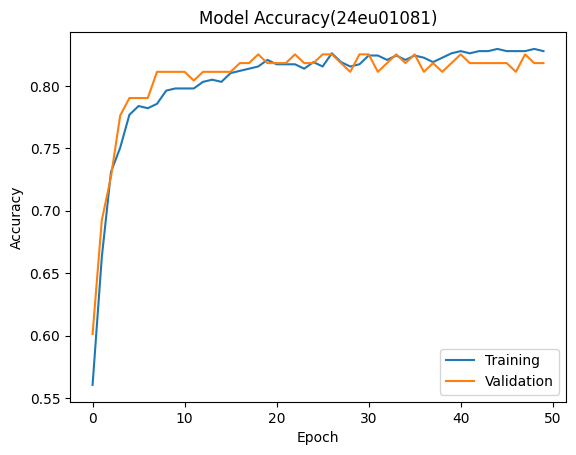

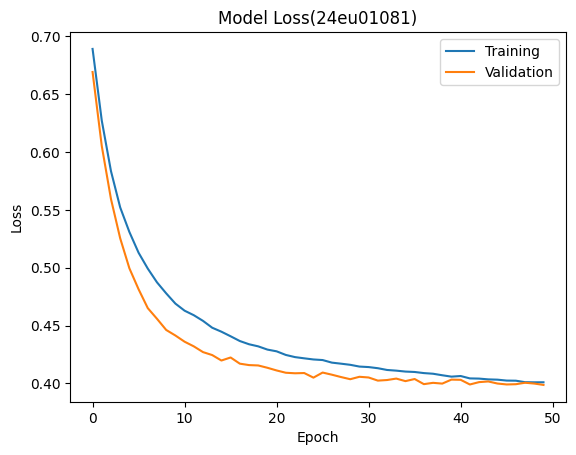

In [7]:
y_pred = model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int)

print("Predictions:")
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy(24eu01081)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Training', 'Validation'])

plt.show()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss(24eu01081)')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Training', 'Validation'])

